<a href="https://colab.research.google.com/github/sebasarellano/Aprendizaje_Automatico/blob/main/04_Agrupamiento_kMeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/andres-merino/AprendizajeAutomaticoInicial-05-N0105/blob/main/2-Ejercicios/04-Agrupamiento-kMeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<table style="border: none; border-collapse: collapse;">
    <tr>
        <td style="width: 20%; vertical-align: middle; padding-right: 10px;">
            <img src="https://i.imgur.com/nt7hloA.png" width="100">
        </td>
        <td style="width: 2px; text-align: center;">
            <font color="#0030A1" size="7">|</font><br>
            <font color="#0030A1" size="7">|</font>
        </td>
        <td>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="5">
                <b>Facultad de Ciencias Exactas, Naturales y Ambientales</b>
            </font> </p>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="4">
                Aprendizaje Automático Inicial &bull; Agrupamiento k-Means
            </font></p>
            <p style="font-style: oblique;"><font color="#0030A1" size="3">
                Sebastián Arellano &bull; 2026-11
            </font></p>
        </td>  
    </tr>
</table>

---
## <font color='264CC7'> Introducción </font>

A lo largo de este taller, aplicaremos el algoritmo de agrupamiento jerárquico a un conjunto de datos.

Los paquetes necesarios son:

In [11]:
!pip install ucimlrepo

# Paquetes necesarios
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)


---
## <font color='264CC7'> Preprocesamiento de datos </font>

Primero necesitas el conjunto de datos. Los datos a utilzar son los seleccionados en la clase aterior.

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Carga el conjunto de datos y procésalos:
<ul>
  <li>Muestra algunos datos.</li>
  <li>Muestra una descripción de los datos.</li>
  <li>Escala los datos si es necesario.</li>
</ul>
</div>

In [4]:
dataset = fetch_ucirepo(id=697)

# Separar características y variable objetivo
X_original = dataset.data.features.copy()
y_original = dataset.data.targets.copy()

df = pd.concat([X_original, y_original], axis=1)
print("Dimensiones del conjunto de datos:", df.shape)

display(df.head())

display(df.describe(include="all").T)

print("\nValores faltantes:")
display(df.isnull().sum().sort_values(ascending=False).head(15))

print("\nDistribución de la variable objetivo:")
display(y_original.value_counts())


Dimensiones del conjunto de datos: (4424, 37)


,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Marital Status,4424.0,NaN,NaN,NaN,1.178571,0.605747,1.0,1.0,1.0,1.0,6.0
Application mode,4424.0,NaN,NaN,NaN,18.669078,17.484682,1.0,1.0,17.0,39.0,57.0
Application order,4424.0,NaN,NaN,NaN,1.727848,1.313793,0.0,1.0,1.0,2.0,9.0
Course,4424.0,NaN,NaN,NaN,8856.642631,2063.566416,33.0,9085.0,9238.0,9556.0,9991.0
Daytime/evening attendance,4424.0,NaN,NaN,NaN,0.890823,0.311897,0.0,1.0,1.0,1.0,1.0
Previous qualification,4424.0,NaN,NaN,NaN,4.577758,10.216592,1.0,1.0,1.0,1.0,43.0
Previous qualification (grade),4424.0,NaN,NaN,NaN,132.613314,13.188332,95.0,125.0,133.1,140.0,190.0
Nacionality,4424.0,NaN,NaN,NaN,1.873192,6.914514,1.0,1.0,1.0,1.0,109.0
Mother's qualification,4424.0,NaN,NaN,NaN,19.561935,15.603186,1.0,2.0,19.0,37.0,44.0
Father's qualification,4424.0,NaN,NaN,NaN,22.275316,15.343108,1.0,3.0,19.0,37.0,44.0



Valores faltantes:


,0
Marital Status,0
Application mode,0
Application order,0
Course,0
Daytime/evening attendance,0
Previous qualification,0
Previous qualification (grade),0
Nacionality,0
Mother's qualification,0
Father's qualification,0



Distribución de la variable objetivo:


,count
Target,
Graduate,2209
Dropout,1421
Enrolled,794


In [5]:
X = X_original.copy()

# Identificar variables categóricas
categoricas = [
    'Marital Status',
    'Application mode',
    'Course',
    'Daytime/evening attendance',
    'Previous qualification',
    'Nacionality',
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation"
]

# Convertir variables categóricas mediante One-Hot Encoding
X = pd.get_dummies(X, columns=categoricas, dtype=int)

# Escalar los datos
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Dimensiones originales:", X_original.shape)
print("Dimensiones después del One-Hot Encoding:", X.shape)
print("Dimensiones después del escalado:", X_scaled.shape)


Dimensiones originales: (4424, 36)
Dimensiones después del One-Hot Encoding: (4424, 248)
Dimensiones después del escalado: (4424, 248)


---
## <font color='264CC7'> Determinación del número de clusters </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Determina el número óptimo de clústeres para un modelo K-Means utilizando el método del codo.
<ul>
  <li>Genera una gráfica que muestre la inercia frente al número de clústeres (k) en el rango de 1 a 10.</li>
  <li>Identifica visualmente el "codo" en la curva para seleccionar el número óptimo de clústeres.</li>
  <li>De manera intuitiva, explica por qué consideras ese punto como el codo y cómo influye en la calidad de los clústeres.</li>
</ul>
</div>


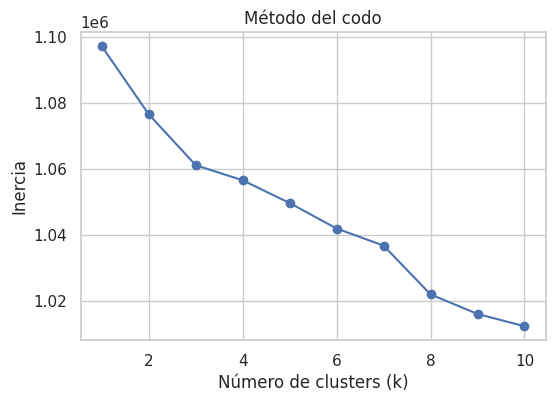

In [6]:
# Método del codo
inertia = []

for i in range(1, 11):
    modelo = KMeans(n_clusters=i, random_state=42)
    modelo.fit(X_scaled)
    inertia.append(modelo.inertia_)

# Graficar resultados
plt.figure(figsize=(6, 4))
plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Inercia')
plt.title('Método del codo')
plt.show()


Elegimos k=3 porque a partir de ese punto se detuvo la disminución de manera significativa que va como de 3 a 7 más o menos, por eso elegimos el número de clusters de 3

---
## <font color='264CC7'> Asignación de grupos y análisis </font>


<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Realiza un análisis de los grupos obtenidos.
<ul>
  <li>Asigna los grupos.</li>
  <li>Revisa la media de cada grupo.</li>
  <li>Revisa el mínimo y máximo de cada grupo.</li>
  <li>Muestra algunos integrantes de cada grupo.</li>
</ul>
</div>

In [7]:
modelo = KMeans(n_clusters=3, random_state=42)
modelo.fit(X_scaled)

# Asignar los grupos
grupos = X_original.copy()
grupos['Cluster'] = modelo.labels_

# Cantidad de estudiantes por grupo
print("Cantidad de estudiantes por grupo:")
print(grupos['Cluster'].value_counts().sort_index())

# Media de cada grupo
print("\nMedia por grupo:")
display(grupos.groupby('Cluster').mean().round(2))

# Valores mínimos y máximos
print("\nValores mínimos:")
display(grupos.groupby('Cluster').min())

print("\nValores máximos:")
display(grupos.groupby('Cluster').max())

# Mostrar algunos integrantes de cada grupo
for i in range(3):
    print(f"\nEstudiantes del grupo {i}:")
    display(grupos[grupos['Cluster'] == i].head())


Cantidad de estudiantes por grupo:
Cluster
0     721
1     718
2    2985
Name: count, dtype: int64

Media por grupo:


,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
Cluster,,,,,,,,,,,,,,,,,,,,,
0,1.15,20.87,1.63,6978.18,0.98,4.44,133.40,1.97,18.47,20.53,...,0.24,0.01,4.26,3.42,0.12,0.76,0.30,11.57,1.31,-0.20
1,1.90,34.43,1.11,9170.59,0.35,7.45,130.21,1.54,30.01,29.81,...,0.18,1.52,6.73,8.98,4.62,10.15,0.21,11.36,1.28,-0.34
2,1.01,14.35,1.90,9234.85,1.00,3.92,133.00,1.93,17.31,20.89,...,0.10,0.44,6.59,8.97,5.43,12.54,0.10,11.62,1.19,0.13



Valores mínimos:


,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
Cluster,,,,,,,,,,,,,,,,,,,,,
0,1,1,1,33,0,1,99.0,1,1,1,...,0,0,0,0,0,0.0,0,7.6,-0.8,-4.06
1,1,1,1,33,0,1,96.0,1,1,1,...,0,0,1,0,0,0.0,0,7.6,-0.8,-4.06
2,1,1,0,33,0,1,95.0,1,1,1,...,0,0,3,0,0,0.0,0,7.6,-0.8,-4.06



Valores máximos:


,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
Cluster,,,,,,,,,,,,,,,,,,,,,
0,6,51,6,9991,1,43,190.0,101,43,43,...,8,2,8,16,4,16.000000,12,16.2,3.7,3.51
1,6,57,9,9991,1,43,180.0,100,43,39,...,12,19,21,33,19,17.692308,12,16.2,3.7,3.51
2,5,53,6,9853,1,43,190.0,109,44,44,...,12,18,23,28,20,18.571429,7,16.2,3.7,3.51


... (2 outputs left out)


Estudiantes del grupo 1:


,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Cluster
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,1
5,2,39,1,9991,0,19,133.1,1,37,37,...,0,5,17,5,11.500000,5,16.2,0.3,-0.92,1
34,1,1,1,9991,0,1,130.0,1,2,37,...,0,5,9,5,13.428571,0,13.9,-0.3,0.79,1
37,1,43,1,9147,1,1,140.0,1,37,37,...,0,5,8,2,12.000000,2,16.2,0.3,-0.92,1
38,4,39,1,9991,0,1,120.0,1,19,19,...,0,5,5,5,11.600000,0,7.6,2.6,0.32,1



Estudiantes del grupo 2:


,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Cluster
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,2
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,2
6,1,1,1,9500,1,1,142.0,1,19,38,...,0,8,8,8,14.345000,0,15.5,2.8,-4.06,2
8,1,1,3,9238,1,1,137.0,62,1,1,...,0,6,7,6,14.142857,0,16.2,0.3,-0.92,2
9,1,1,1,9238,1,1,138.0,1,1,19,...,0,6,14,2,13.500000,0,8.9,1.4,3.51,2


<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Da una descripción de los grupos obtenidos. Asigna un nombre a cada grupo.
</div>

- Cluster 0 (721 estudiantes): Grupo minoritario caracterizado por un menor número de asignaturas matriculadas y evaluadas en el segundo semestre, así como un promedio de calificaciones relativamente bajo (0.76).

- Cluster 1 (718 estudiantes): Grupo con menor participación académica en el primer semestre, pero con mayor actividad en el segundo semestre. Presenta un promedio de calificaciones de 10.15.

- Cluster 2 (2985 estudiantes): Es el grupo más numeroso. Presenta mayor cantidad de asignaturas aprobadas en el segundo semestre y el promedio de calificaciones más alto (12.54).

---
## <font color='264CC7'> Visualizaciones  </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Realiza una visualización de los grupos obtenidos en 2D seleccionando dos variables que creas relevantes.
<ul>
  <li>¿Qué tan buenos te parecen los grupos?</li>
</ul>
</div>

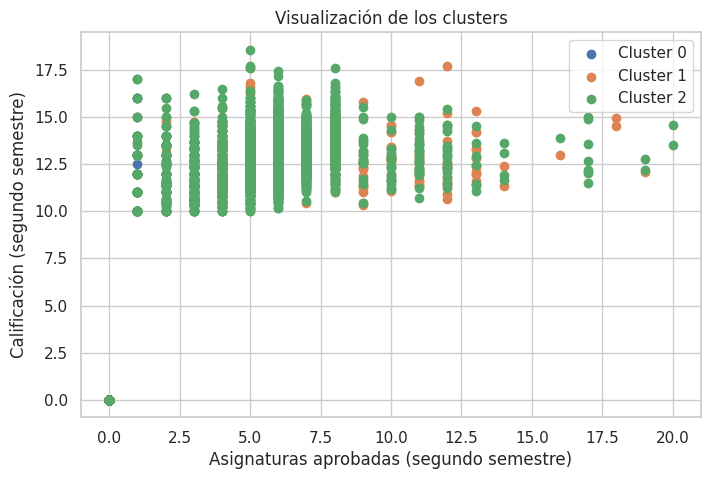

In [10]:
# Visualización de los clusters
plt.figure(figsize=(8, 5))

for i in range(3):
    datos = grupos[grupos['Cluster'] == i]

    plt.scatter(
        datos['Curricular units 2nd sem (approved)'],
        datos['Curricular units 2nd sem (grade)'],
        label=f'Cluster {i}'
    )

plt.xlabel('Asignaturas aprobadas (segundo semestre)')
plt.ylabel('Calificación (segundo semestre)')
plt.title('Visualización de los clusters')
plt.legend()
plt.show()

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Realiza una visualización de los grupos obtenidos en 2D usando reducción de dimensionalidad diferente a PCA.
<ul>
  <li>¿Qué tan buenos te parecen los grupos?</li>
  <li>Indica el porcentaje de la variaza explicada en el gráfico, ¿afecta esto a tu visualización?</li>
</ul>
</div>

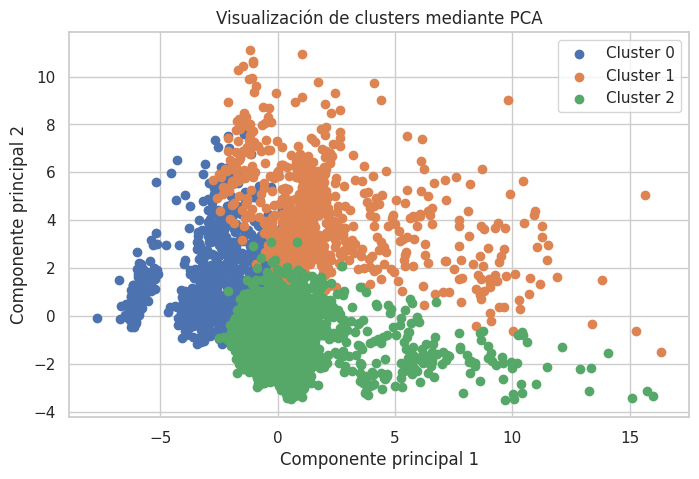

Varianza explicada: [0.02720089 0.02545555]
Varianza acumulada: 0.052656431808949564


In [12]:
# Aplicar PCA con dos componentes
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Visualizar los clusters
plt.figure(figsize=(8, 5))

for i in range(3):
    plt.scatter(
        X_pca[modelo.labels_ == i, 0],
        X_pca[modelo.labels_ == i, 1],
        label=f'Cluster {i}'
    )

plt.xlabel('Componente principal 1')
plt.ylabel('Componente principal 2')
plt.title('Visualización de clusters mediante PCA')
plt.legend()
plt.show()

# Varianza explicada
print("Varianza explicada:", pca.explained_variance_ratio_)
print("Varianza acumulada:", pca.explained_variance_ratio_.sum())


Bueno como el dataset que elegí contaba con muchas variables, al reducirlo solo a 2 para poder graficarlo en ninguno de los dos casos nos da 3 grupos muy marcados, sin embargo con la utilización de PCA para seleccionar las dos componentes si hay una mejora notoria, ya que en el anterior que yo seleccione unas variables discretas no se nota ninguna diferencia entre grupos como si sucede en la segunda visualización

---
## <font color='264CC7'> Métricas  </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Calcula la métrica de la silueta para los grupos obtenidos. ¿Qué tan buenos te parecen los grupos?
</div>

In [13]:
# Calcular coeficiente de silueta
silueta = silhouette_score(X_scaled, modelo.labels_)

print("Coeficiente de silueta:", round(silueta, 4))

Coeficiente de silueta: 0.0875


Bueno el coeficiente de silueta nos dio positivo aunque muy cercano a 0, esto nos indica que nuestro agrupamiento por K-means fue regular y no hay grupos muy marcados entre si.